In [22]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [23]:
import json
from pathlib import Path
import pandas as pd

rows = [json.load(open(p)) for p in Path("models").glob("lora_*/metrics.json")]
runs = pd.DataFrame(rows).sort_values("rank")
runs[
    [
        "rank",
        "alpha",
        "trainable_params",
        "train_loss",
        "eval_loss",
        "best_step",
        "minutes",
        "peak_mem_gb",
    ]
]

,rank,alpha,trainable_params,train_loss,eval_loss,best_step,minutes,peak_mem_gb
2,4,8,2199552,1.3738,1.3303,900,18.6,11.17
1,16,32,8798208,1.3600,1.3091,900,17.9,11.25
0,64,128,35192832,1.3785,1.2978,921,18.0,11.56


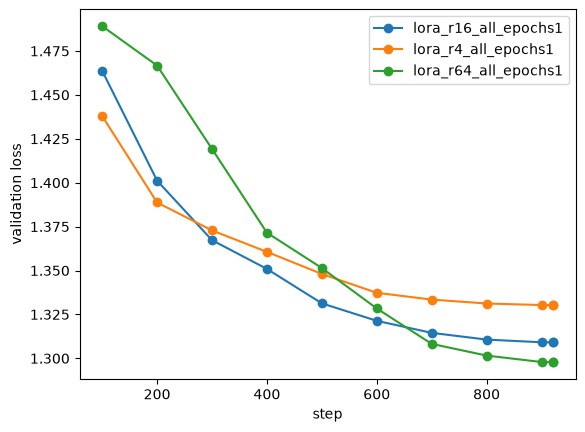

In [24]:
import matplotlib.pyplot as plt

for p in sorted(Path("models").glob("lora_*/log_history.json")):
    log = json.load(open(p))
    evals = [e for e in log if "eval_loss" in e]
    plt.plot(
        [e["step"] for e in evals],
        [e["eval_loss"] for e in evals],
        marker="o",
        label=p.parent.name,
    )
plt.xlabel("step")
plt.ylabel("validation loss")
plt.legend()
plt.show()

In [3]:
import json
from pathlib import Path
import pandas as pd
!pip install tabulate
import tabulate


def load(pattern):
    return {p.parent.name: json.load(open(p)) for p in Path(".").glob(pattern)}


rouge = load("results/*_validation/metrics.json")
mmlu = load("results/mmlu_*/metrics.json")
train = load("models/*/metrics.json")
base_mmlu = mmlu.get("mmlu_base_1000questions", {})

rows = []
for name, m in rouge.items():
    if name.startswith(("icl_", "base_")):
        label = f"{m['shots']}-shot"
        mmlu_row = base_mmlu
        train_row = {}

    elif name.startswith("lora_"):
        run = name.split("_0shot")[0]
        r = run.split("_r")[1]
        label = f"LoRA r={r}"
        mmlu_row = mmlu.get(f"mmlu_{run}_1000questions", {})
        train_row = train.get(f"lora_r{r}_all_epochs1", {})
    elif name.startswith("full_"):
        # Full fine-tune. Its run crashed before writing metrics.json,
        # so the training numbers come from the training log instead.
        label = "Full FT"
        mmlu_row = mmlu.get("mmlu_full_1000questions", {})
        train_row = {
            "trainable_params": 494032768,  # every weight
            "minutes": 24.9,  # 24:51 min for 920/921 before ran out of memory
            "peak_mem_gb": ">14.5",
            "eval_loss": "1.312",
        }
    elif name.startswith("qlora_"):
        run = name.split("_0shot")[0]  # qlora_r16
        r = run.split("_r")[1]  # 16
        label = f"QLoRA r={r}"
        mmlu_row = mmlu.get(f"mmlu_{run}_1000questions", {})
        train_row = train.get(f"qlora_r{r}_all_epochs1", {})
    else:
        continue
    rows.append(
        {
            "method": label,
            "rouge1": round(100 * m["rouge1"], 1),  # ×100 → the 0–100 scale papers use
            "rouge2": round(100 * m["rouge2"], 1),
            "rougeL": round(100 * m["rougeL"], 1),
            "mmlu": mmlu_row.get("accuracy"),  # already in %
            "trainable_params": train_row.get("trainable_params"),
            "train_min": train_row.get("minutes"),
            "peak_mem_gb": train_row.get("peak_mem_gb"),
            "eval_min": m["minutes"],  # time to generate + score the 818 summaries
            "eval_loss": train_row.get("eval_loss"),
        }
    )

order = [
    "0-shot",
    "1-shot",
    "3-shot",
    "5-shot",
    "LoRA r=4",
    "LoRA r=16",
    "LoRA r=64",
    "QLoRA r=16",
    "Full FT",
]
table = pd.DataFrame(rows).sort_values("method")
table = table.set_index("method").loc[order].reset_index()
table["trainable_params"] = table["trainable_params"].astype("Int64")
print(table.to_markdown(index=False))


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
| method     |   rouge1 |   rouge2 |   rougeL |   mmlu | trainable_params   |   train_min | peak_mem_gb   |   eval_min |   eval_loss |
|:-----------|---------:|---------:|---------:|-------:|:-------------------|------------:|:--------------|-----------:|------------:|
| 0-shot     |     33.8 |     10   |     25.2 |   41.1 | <NA>               |       nan   |               |       18.4 |             |
| 1-shot     |     35   |     11.4 |     27.7 |   41.1 | <NA>               |       nan   |               |       10.9 |             |
| 3-shot     |     38.4 |     13.2 |     29.7 |   41.1 | <NA>               |       nan   |               |       15.9 |             |
| 5-shot     |     38.9 |     13.8 |     29.8 |   41.1 | <NA>               |       nan   |               |       18   |             |
| LoRA r=4   |     47.1 |     20.6 |     37.3 |   40.6 | 2199552            |  

In [4]:
import json
from pathlib import Path
import pandas as pd

rows = []
for quant in ["none", "8bit", "4bit"]:
    with open(f"results/lora_r16_{quant}_0shot_validation/metrics.json") as f:
        rouge = json.load(f)
    with  open(f"results/mmlu_lora_r16_{quant}_1000questions/metrics.json") as f:
        mmlu = json.load(f)
    rows.append({
        "quant": quant,
        "model_mem_gb": rouge["model_mem_gb"],
        "peak_gen_gb": rouge["peak_mem_gb"],    # peak while generating summaries
        "peak_mmlu_gb": mmlu["peak_mem_gb"],    # peak while scoring MMLU
        "rouge1": round(100 * rouge["rouge1"], 1),
        "rouge2": round(100 * rouge["rouge2"], 1),
        "rougeL": round(100 * rouge["rougeL"], 1),
        "mmlu": mmlu["accuracy"],
        "rouge_min": rouge["minutes"],
        "mmlu_min": mmlu["minutes"],
    })

quant_table = pd.DataFrame(rows)
print(quant_table.to_markdown(index=False))

| quant   |   model_mem_gb |   peak_gen_gb |   peak_mmlu_gb |   rouge1 |   rouge2 |   rougeL |   mmlu |   rouge_min |   mmlu_min |
|:--------|---------------:|--------------:|---------------:|---------:|---------:|---------:|-------:|------------:|-----------:|
| none    |           1.02 |          1.14 |           1.5  |     47.1 |     21.3 |     37.7 |   41.7 |        21.9 |        1.2 |
| 8bit    |           0.67 |          0.77 |           1.13 |     47.5 |     21.3 |     37.7 |   40.5 |        59.1 |        3.3 |
| 4bit    |           0.49 |          0.6  |           0.96 |     46.2 |     20   |     36.6 |   40.4 |        30.5 |        1.8 |


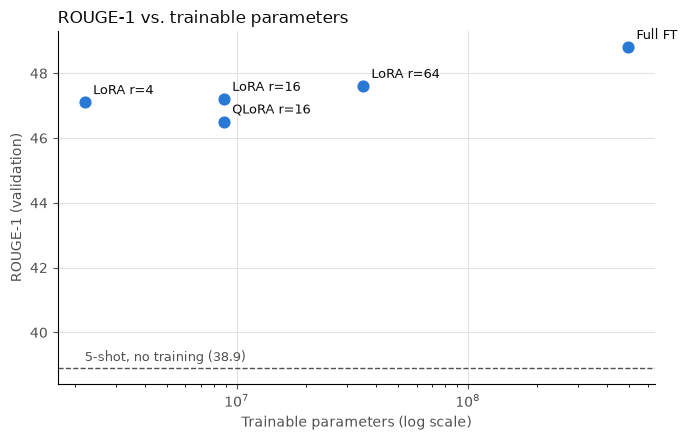

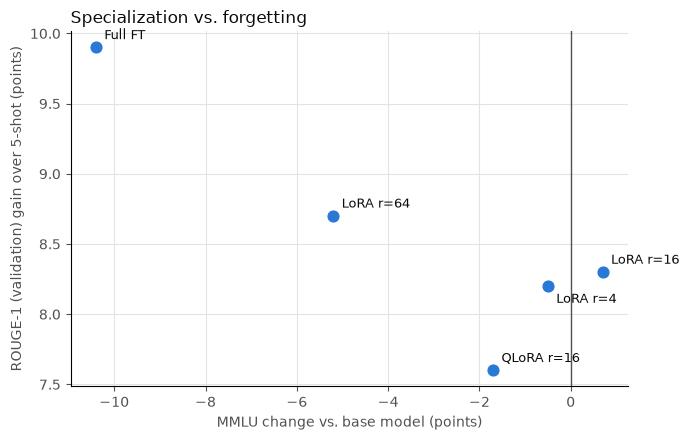

In [27]:
from pathlib import Path

import matplotlib.pyplot as plt

POINT = "#2a78d6"
INK = "#0b0b0b"        # labels and titles
INK_2 = "#52514e"      # axis text, reference lines
GRID = "#e4e3df"

Path("figures").mkdir(exist_ok=True)
t = table.set_index("method")
trained = ["LoRA r=4", "LoRA r=16", "LoRA r=64", "QLoRA r=16", "Full FT"]

def style(ax, xlabel, ylabel, title):
    ax.set_xlabel(xlabel, color=INK_2)
    ax.set_ylabel(ylabel, color=INK_2)
    ax.set_title(title, color=INK, loc="left", fontsize=12)
    ax.grid(True, color=GRID,linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(colors=INK_2)

# Plot 1: ROUGE-1 vs trainable params
fig, ax = plt.subplots(figsize=(7, 4.5))
x = [t.loc[m, "trainable_params"] for m in trained]
y = [t.loc[m, "rouge1"] for m in trained]
ax.scatter(x, y, s=60, color=POINT, zorder=3)
for m, xi, yi in zip(trained, x, y):
    ax.annotate(m, (xi, yi), textcoords="offset points", xytext=(6,6), color=INK, fontsize=9)

best_shot = t.loc["5-shot", "rouge1"]
ax.axhline(best_shot, color=INK_2, linestyle="--", linewidth=1)
ax.annotate(f"5-shot, no training ({best_shot})", (min(x), best_shot), textcoords="offset points", xytext=(0,5), color=INK_2, fontsize=9)

ax.set_xscale("log")
style(ax, "Trainable parameters (log scale)", "ROUGE-1 (validation)", "ROUGE-1 vs. trainable parameters")
fig.tight_layout()
fig.savefig("figures/rouge_val_vs_params.png", dpi=200)
plt.show()

# Plot 2: ROUGE-1 gain vs MMLU change
base_mmlu = t.loc["0-shot", "mmlu"]
fig, ax = plt.subplots(figsize=(7, 4.5))
rouge_gain = [t.loc[m, "rouge1"] - best_shot for m in trained]
mmlu_change = [t.loc[m, "mmlu"] - base_mmlu for m in trained]
ax.scatter(mmlu_change, rouge_gain, s=60, color=POINT, zorder=3)
for m, xi, yi in zip(trained, mmlu_change, rouge_gain):
    offset = (6, -12) if m == "LoRA r=4" else (6,6)
    ax.annotate(m, (xi,yi), textcoords="offset points", xytext=offset, color=INK, fontsize=9)

ax.axvline(0, color=INK_2, linewidth=1) # no change
style(ax, "MMLU change vs. base model (points)", "ROUGE-1 (validation) gain over 5-shot (points)", "Specialization vs. forgetting")
fig.tight_layout()
fig.savefig("figures/rouge_gain_val_vs_forgetting.png", dpi=200)
plt.show()

In [5]:
import json
from pathlib import Path
import pandas as pd


def load(pattern):
    return {p.parent.name: json.load(open(p)) for p in Path(".").glob(pattern)}


rouge = load("results/*_test/metrics.json")
mmlu = load("results/mmlu_*/metrics.json")
train = load("models/*/metrics.json")
base_mmlu = mmlu.get("mmlu_base_1000questions", {})

rows = []
for name, m in rouge.items():
    if name.startswith(("icl_", "base_")):
        label = f"{m['shots']}-shot"
        mmlu_row = base_mmlu
        train_row = {}

    elif name.startswith("lora_"):
        run = name.split("_0shot")[0]
        r = run.split("_r")[1]
        label = f"LoRA r={r}"
        mmlu_row = mmlu.get(f"mmlu_{run}_1000questions", {})
        train_row = train.get(f"lora_r{r}_all_epochs1", {})
    elif name.startswith("full_"):
        # Full fine-tune. Its run crashed before writing metrics.json,
        # so the training numbers come from the training log instead.
        label = "Full FT"
        mmlu_row = mmlu.get("mmlu_full_1000questions", {})
        train_row = {
            "trainable_params": 494032768,  # every weight
            "minutes": 24.9,  # 24:51 min for 920/921 before ran out of memory
            "peak_mem_gb": ">14.5",
            "eval_loss": "1.312",
        }
    elif name.startswith("qlora_"):
        run = name.split("_0shot")[0]  # qlora_r16
        r = run.split("_r")[1]  # 16
        label = f"QLoRA r={r}"
        mmlu_row = mmlu.get(f"mmlu_{run}_1000questions", {})
        train_row = train.get(f"qlora_r{r}_all_epochs1", {})
    else:
        continue
    rows.append(
        {
            "method": label,
            "rouge1": round(100 * m["rouge1"], 1),  # ×100 → the 0–100 scale papers use
            "rouge2": round(100 * m["rouge2"], 1),
            "rougeL": round(100 * m["rougeL"], 1),
            "mmlu": mmlu_row.get("accuracy"),  # already in %
            "trainable_params": train_row.get("trainable_params"),
            "train_min": train_row.get("minutes"),
            "peak_mem_gb": train_row.get("peak_mem_gb"),
            "eval_min": m["minutes"],  # time to generate + score the summaries
            "eval_loss": train_row.get("eval_loss"),
        }
    )

order = [
    "0-shot",
    "1-shot",
    "3-shot",
    "5-shot",
    "LoRA r=4",
    "LoRA r=16",
    "LoRA r=64",
    "QLoRA r=16",
    "Full FT",
]
order = [m for m in order if m in set(row["method"] for row in rows)]
test_table = pd.DataFrame(rows).sort_values("method")
test_table = test_table.set_index("method").loc[order].reset_index()
test_table["trainable_params"] = test_table["trainable_params"].astype("Int64")
print(test_table.to_markdown(index=False))

| method     |   rouge1 |   rouge2 |   rougeL |   mmlu | trainable_params   |   train_min | peak_mem_gb   |   eval_min |   eval_loss |
|:-----------|---------:|---------:|---------:|-------:|:-------------------|------------:|:--------------|-----------:|------------:|
| 5-shot     |     37.4 |     12.5 |     28.4 |   41.1 | <NA>               |       nan   |               |       17.2 |             |
| LoRA r=16  |     46.4 |     19.7 |     36.9 |   41.8 | 8798208            |        17.9 | 11.25         |       21.6 |      1.3091 |
| LoRA r=64  |     47.1 |     20.7 |     37.7 |   35.9 | 35192832           |        18   | 11.56         |       21.5 |      1.2978 |
| QLoRA r=16 |     45.4 |     19   |     36.4 |   39.4 | 8798208            |        26.4 | 10.9          |       21.8 |      1.3277 |
| Full FT    |     47.9 |     21.8 |     38.7 |   30.7 | 494032768          |        24.9 | >14.5         |       10.9 |      1.312  |


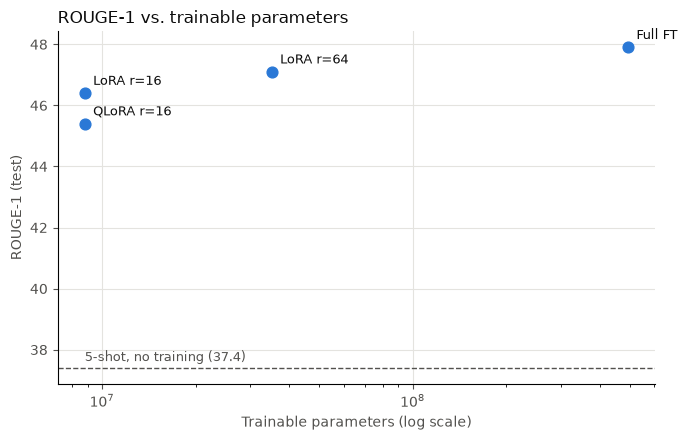

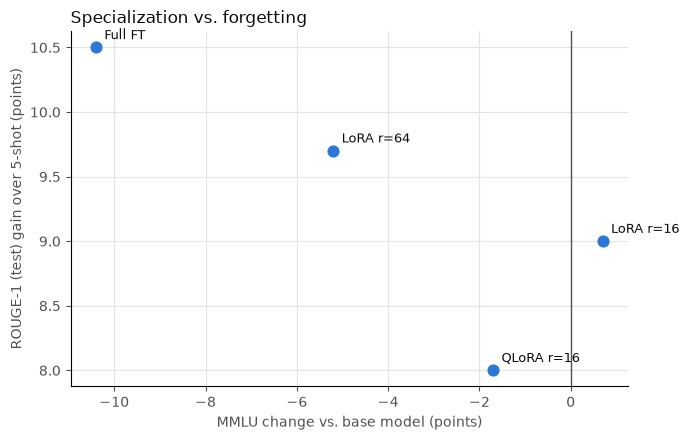

In [29]:
from pathlib import Path

import matplotlib.pyplot as plt

POINT = "#2a78d6"
INK = "#0b0b0b"        # labels and titles
INK_2 = "#52514e"      # axis text, reference lines
GRID = "#e4e3df"

Path("figures").mkdir(exist_ok=True)
t = test_table.set_index("method")
trained = ["LoRA r=16", "LoRA r=64", "QLoRA r=16", "Full FT"]

def style(ax, xlabel, ylabel, title):
    ax.set_xlabel(xlabel, color=INK_2)
    ax.set_ylabel(ylabel, color=INK_2)
    ax.set_title(title, color=INK, loc="left", fontsize=12)
    ax.grid(True, color=GRID,linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(colors=INK_2)

# Plot 1: ROUGE-1 vs trainable params
fig, ax = plt.subplots(figsize=(7, 4.5))
x = [t.loc[m, "trainable_params"] for m in trained]
y = [t.loc[m, "rouge1"] for m in trained]
ax.scatter(x, y, s=60, color=POINT, zorder=3)
for m, xi, yi in zip(trained, x, y):
    ax.annotate(m, (xi, yi), textcoords="offset points", xytext=(6,6), color=INK, fontsize=9)

best_shot = t.loc["5-shot", "rouge1"]
ax.axhline(best_shot, color=INK_2, linestyle="--", linewidth=1)
ax.annotate(f"5-shot, no training ({best_shot})", (min(x), best_shot), textcoords="offset points", xytext=(0,5), color=INK_2, fontsize=9)

ax.set_xscale("log")
style(ax, "Trainable parameters (log scale)", "ROUGE-1 (test)", "ROUGE-1 vs. trainable parameters")
fig.tight_layout()
fig.savefig("figures/rouge_test_vs_params.png", dpi=200)
plt.show()

# Plot 2: ROUGE-1 gain vs MMLU change
base_mmlu = mmlu["mmlu_base_1000questions"]["accuracy"]
fig, ax = plt.subplots(figsize=(7, 4.5))
rouge_gain = [t.loc[m, "rouge1"] - best_shot for m in trained]
mmlu_change = [t.loc[m, "mmlu"] - base_mmlu for m in trained]
ax.scatter(mmlu_change, rouge_gain, s=60, color=POINT, zorder=3)
for m, xi, yi in zip(trained, mmlu_change, rouge_gain):
    ax.annotate(m, (xi,yi), textcoords="offset points", xytext=(6, 6), color=INK, fontsize=9)

ax.axvline(0, color=INK_2, linewidth=1) # no change
style(ax, "MMLU change vs. base model (points)", "ROUGE-1 (test) gain over 5-shot (points)", "Specialization vs. forgetting")
fig.tight_layout()
fig.savefig("figures/rouge_gain_test_vs_forgetting.png", dpi=200)
plt.show()

In [6]:
from datasets import load_dataset
ds = load_dataset("knkarthick/samsum")
print({split: len(ds[split]) for split in ds})

/Users/fernandoquintino/Documents/CS files/DeepLearning AI courses/Small_course_projects/summ-ft/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'train': 14731, 'validation': 818, 'test': 819}
